In [1]:

# ============================================================
# CELDA 1. CARGA Y PREPARACIÓN DE DATOS
# EDA INICIAL: DISTRIBUCIÓN DE RETRASOS
# ============================================================

# Importamos las librerías necesarias para analizar
# los retrasos de salida de los vuelos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
from IPython.display import display

# Conectamos Google Drive para utilizar el mismo archivo
# que emplearon los otros integrantes del equipo.
drive.mount("/content/drive")

# Ruta de la muestra histórica de BTS de 2024 y 2025.
# Contiene 5,000 vuelos aleatorios por mes.
RUTA_DATOS = Path(
    "/content/drive/MyDrive/flight_delay_bigdata/"
    "sample/muestra_historica_bts.parquet"
)

# Comprobamos que el archivo exista.
if not RUTA_DATOS.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {RUTA_DATOS}"
    )

# Cargamos la muestra completa sin volver a descargar
# los archivos originales de BTS.
df = pd.read_parquet(RUTA_DATOS)

# Estandarizamos los nombres de las columnas.
df.columns = df.columns.str.strip().str.upper()

# Revisamos que existan las columnas que necesitamos.
columnas_necesarias = ["DEPDELAY", "CANCELLED"]

faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in df.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias: {faltantes}"
    )

# Creamos una copia para trabajar sin modificar el original.
eda = df.copy()

# Convertimos los valores a números.
eda["DEPDELAY"] = pd.to_numeric(
    eda["DEPDELAY"],
    errors="coerce"
)

eda["CANCELLED"] = pd.to_numeric(
    eda["CANCELLED"],
    errors="coerce"
)

# Excluimos los vuelos cancelados porque no tienen
# un retraso de salida comparable con los demás.
eda = eda[
    (eda["CANCELLED"] == 0) &
    (eda["DEPDELAY"].notna())
].copy()

# Identificamos los vuelos retrasados 15 minutos o más.
# Este será el mismo criterio utilizado por el equipo.
eda["delayed_15"] = (
    eda["DEPDELAY"] >= 15
).astype(int)

# Calculamos algunas estadísticas generales.
print("RESUMEN DE LA MUESTRA")
print("-" * 45)

print("Vuelos originales:", f"{len(df):,}")
print("Vuelos válidos:", f"{len(eda):,}")

print(
    "Vuelos retrasados >= 15 min:",
    f"{eda['delayed_15'].sum():,}"
)

print(
    "Porcentaje de retrasados:",
    f"{eda['delayed_15'].mean() * 100:.2f}%"
)

print(
    "Mediana del retraso:",
    f"{eda['DEPDELAY'].median():.2f} minutos"
)

print(
    "Retraso máximo registrado:",
    f"{eda['DEPDELAY'].max():.0f} minutos"
)

# Revisamos los primeros registros procesados.
display(
    eda[
        ["DEPDELAY", "CANCELLED", "delayed_15"]
    ].head()
)


Mounted at /content/drive
RESUMEN DE LA MUESTRA
---------------------------------------------
Vuelos originales: 120,000
Vuelos válidos: 118,255
Vuelos retrasados >= 15 min: 24,905
Porcentaje de retrasados: 21.06%
Mediana del retraso: -2.00 minutos
Retraso máximo registrado: 2674 minutos


,DEPDELAY,CANCELLED,delayed_15
0,-20.0,0.0,0
1,-7.0,0.0,0
2,-4.0,0.0,0
3,-4.0,0.0,0
4,-2.0,0.0,0


DISTRIBUCIÓN DE RETRASOS POSITIVOS
---------------------------------------------
Vuelos con retraso positivo: 44,366
Retraso promedio: 43.70 minutos
Mediana: 18.00 minutos
Percentil 90: 106.00 minutos
Retraso máximo: 2674 minutos


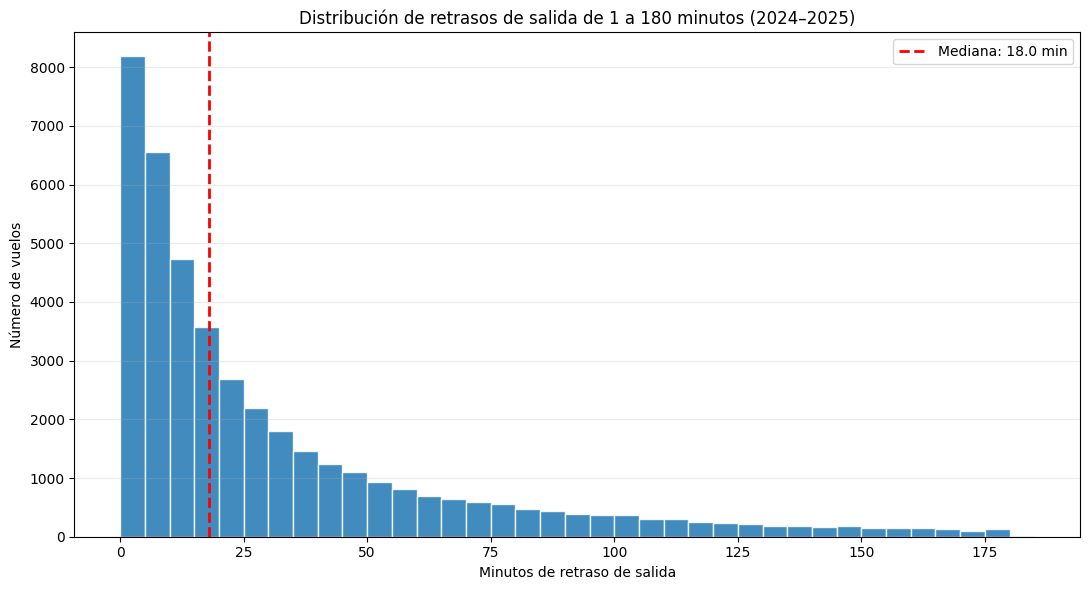

Vuelos con retrasos mayores a 180 minutos: 1,714
Porcentaje de retrasos positivos mayores a 180 minutos: 3.86%


In [2]:

# ============================================================
# CELDA 2. DISTRIBUCIÓN DE LOS MINUTOS DE RETRASO
# ============================================================

# Seleccionamos solamente los vuelos con retraso positivo.
# Los vuelos que salieron antes o puntuales no tienen
# minutos positivos de retraso para esta distribución.
retrasos_positivos = eda.loc[
    eda["DEPDELAY"] > 0,
    "DEPDELAY"
]

# Calculamos algunas estadísticas para interpretar
# cómo se distribuyen los retrasos.
print("DISTRIBUCIÓN DE RETRASOS POSITIVOS")
print("-" * 45)

print(
    "Vuelos con retraso positivo:",
    f"{len(retrasos_positivos):,}"
)

print(
    "Retraso promedio:",
    f"{retrasos_positivos.mean():.2f} minutos"
)

print(
    "Mediana:",
    f"{retrasos_positivos.median():.2f} minutos"
)

print(
    "Percentil 90:",
    f"{retrasos_positivos.quantile(0.90):.2f} minutos"
)

print(
    "Retraso máximo:",
    f"{retrasos_positivos.max():.0f} minutos"
)

# Mostramos en la gráfica solamente los retrasos
# de hasta 180 minutos para facilitar la visualización.
# Los valores superiores permanecen en el dataset.
retrasos_visibles = retrasos_positivos[
    retrasos_positivos <= 180
]

plt.figure(figsize=(11, 6))

# Construimos un histograma con intervalos de 5 minutos.
plt.hist(
    retrasos_visibles,
    bins=np.arange(0, 186, 5),
    edgecolor="white",
    alpha=0.85
)

# Agregamos una línea que indica la mediana general
# de todos los retrasos positivos.
plt.axvline(
    retrasos_positivos.median(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=(
        f"Mediana: "
        f"{retrasos_positivos.median():.1f} min"
    )
)

plt.title(
    "Distribución de retrasos de salida de 1 a 180 minutos (2024–2025)"
)

plt.xlabel("Minutos de retraso de salida")
plt.ylabel("Número de vuelos")
plt.legend()
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Cuantificamos los casos que no se muestran en la gráfica.
extremos = (retrasos_positivos > 180).sum()

print(
    "Vuelos con retrasos mayores a 180 minutos:",
    f"{extremos:,}"
)

print(
    "Porcentaje de retrasos positivos mayores a 180 minutos:",
    f"{extremos / len(retrasos_positivos) * 100:.2f}%"
)


### Interpretación: distribución de minutos de retraso

La distribución muestra que la mayoría de los vuelos que salieron tarde tuvieron retrasos de pocos minutos. Conforme aumentan los minutos de demora, la cantidad de vuelos disminuye, formando una distribución asimétrica hacia la derecha.

La mediana de los retrasos positivos fue de 18 minutos, lo que significa que aproximadamente la mitad de estos vuelos presentó demoras de hasta 18 minutos. También encontramos retrasos extremos, con un máximo de 2,674 minutos (más de 44 horas). En total, 1,714 vuelos registraron retrasos superiores a 180 minutos.

Este comportamiento nos indica que los retrasos no se distribuyen de manera uniforme y que existen casos extremos que debemos considerar al desarrollar los modelos. Más adelante podremos evaluar si distribuciones como la exponencial, gamma o lognormal se ajustan a estos datos.

DISTRIBUCIÓN DE VUELOS POR RANGO DE RETRASO


,Rango,Vuelos,Porcentaje
0,Anticipado o puntual (≤ 0 min),73889,62.48
1,Retraso leve (1–14 min),19461,16.46
2,Retraso moderado (15–59 min),15804,13.36
3,Retraso alto (60–180 min),7387,6.25
4,Retraso extremo (> 180 min),1714,1.45


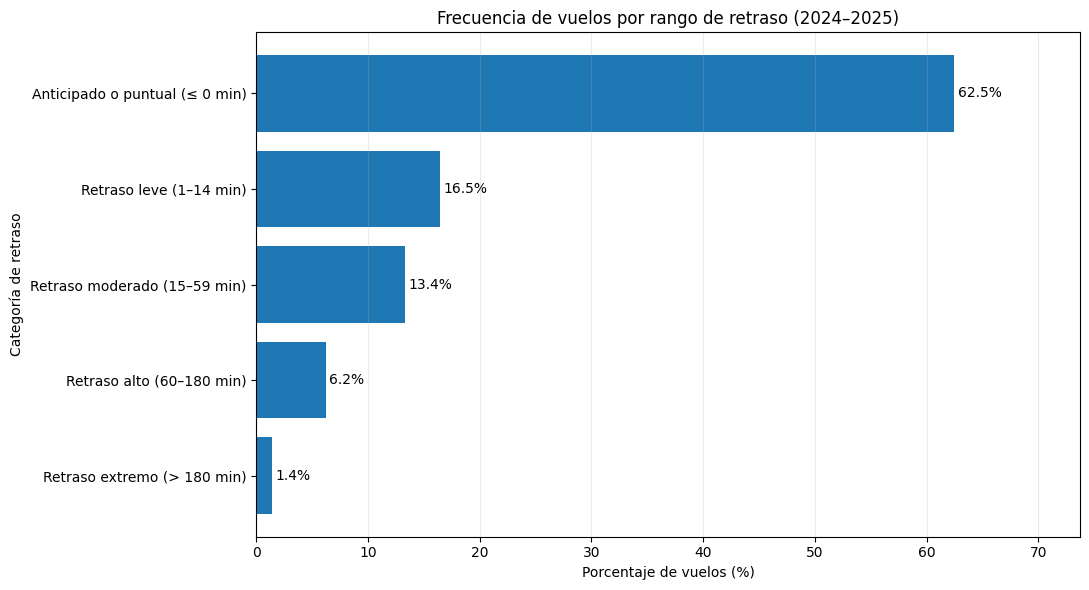

Porcentaje de vuelos retrasados ≥ 15 minutos: 21.06%


In [3]:

# ============================================================
# CELDA 3. FRECUENCIA DE RETRASOS POR RANGOS
# ============================================================

# Clasificamos los vuelos según los minutos de retraso.
# Utilizamos el mismo umbral de 15 minutos definido
# para el problema de clasificación del proyecto.

rangos = [
    "Anticipado o puntual (≤ 0 min)",
    "Retraso leve (1–14 min)",
    "Retraso moderado (15–59 min)",
    "Retraso alto (60–180 min)",
    "Retraso extremo (> 180 min)"
]

# Convertimos los minutos de retraso a categorías.
eda["rango_retraso"] = pd.cut(
    eda["DEPDELAY"],
    bins=[-np.inf, 0, 14, 59, 180, np.inf],
    labels=rangos,
    include_lowest=True
)

# Calculamos cuántos vuelos hay en cada rango.
frecuencia_rangos = (
    eda["rango_retraso"]
    .value_counts()
    .reindex(rangos)
)

# Calculamos el porcentaje respecto al total de vuelos.
porcentaje_rangos = (
    frecuencia_rangos / len(eda) * 100
)

# Creamos una tabla resumen.
tabla_rangos = pd.DataFrame({
    "Rango": rangos,
    "Vuelos": frecuencia_rangos.values,
    "Porcentaje": porcentaje_rangos.values
})

print("DISTRIBUCIÓN DE VUELOS POR RANGO DE RETRASO")

display(tabla_rangos.round(2))

# Generamos una gráfica de barras horizontales.
plt.figure(figsize=(11, 6))

barras = plt.barh(
    tabla_rangos["Rango"],
    tabla_rangos["Porcentaje"]
)

# Mostramos el porcentaje al final de cada barra.
for barra, porcentaje in zip(
    barras,
    tabla_rangos["Porcentaje"]
):
    plt.text(
        barra.get_width() + 0.3,
        barra.get_y() + barra.get_height() / 2,
        f"{porcentaje:.1f}%",
        va="center"
    )

plt.title(
    "Frecuencia de vuelos por rango de retraso (2024–2025)"
)

plt.xlabel("Porcentaje de vuelos (%)")
plt.ylabel("Categoría de retraso")

plt.xlim(0, tabla_rangos["Porcentaje"].max() * 1.18)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# Comprobamos qué porcentaje de vuelos supera
# el umbral de 15 minutos de retraso.
print(
    "Porcentaje de vuelos retrasados ≥ 15 minutos:",
    f"{eda['delayed_15'].mean() * 100:.2f}%"
)


### Interpretación: frecuencia de retrasos por rangos

Al clasificar los vuelos por minutos de retraso, encontramos que el 62.5% salió puntual o antes de su horario programado. Otro 16.5% presentó retrasos leves de entre 1 y 14 minutos, mientras que el 13.4% tuvo retrasos moderados de entre 15 y 59 minutos.

Los retrasos más prolongados fueron menos frecuentes: el 6.2% de los vuelos tuvo demoras de entre 60 y 180 minutos, y aproximadamente el 1.4% superó las tres horas. En total, el 21.06% de los vuelos presentó retrasos de al menos 15 minutos.

Estos resultados también nos ayudan a entender nuestro problema de clasificación, ya que aproximadamente uno de cada cinco vuelos pertenece a la categoría de retrasado. Esto será importante al evaluar los modelos, especialmente con métricas como recall, precisión y F1-score.

### Conclusión del análisis exploratorio

Este análisis nos permitió identificar que los retrasos de salida tienen una distribución asimétrica, donde predominan las demoras pequeñas y existe una menor cantidad de casos extremos. Aunque la mayoría de los vuelos sale puntual o con pocos minutos de diferencia, aproximadamente el 21% supera el umbral de 15 minutos que utilizaremos para nuestro modelo predictivo.

Consideramos que será importante analizar tanto la probabilidad de que ocurra un retraso como su duración, ya que los casos extremos pueden afectar considerablemente la operación aérea. Estos resultados servirán como referencia para los modelos de clasificación y para el análisis estadístico que desarrollaremos posteriormente.